In [87]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupShuffleSplit

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

2. ĐỌc dữ liệu

In [57]:
df_data = pd.read_csv("../Data/dataset.csv")

df_data.info()
print("Kích thước dữ liệu:", df_data.shape)
df_data.head(5)


<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


Làm sạch dữ liệu

In [58]:

# Giữ một bản ghi cho mỗi mã bài hát
df_data = df_data.drop_duplicates(subset="track_id")

# Lấy 4 cột cần dùng
columns = ["energy","valence","tempo","popularity"]
df_data = df_data[columns].copy()
df_data.head(5)

,energy,valence,tempo,popularity
0,0.4610,0.715,87.917,73
1,0.1660,0.267,77.489,55
2,0.3590,0.120,76.332,57
3,0.0596,0.143,181.740,71
4,0.4430,0.167,119.949,82


In [59]:
# Chuyển về số; giá trị không hợp lệ trở thành NaN
for col in columns:
    df_data[col] = pd.to_numeric(df_data[col], errors="coerce")

In [60]:
# Bỏ giá trị vô cực và no data
df_data = df_data.replace([np.inf, -np.inf], np.nan)
df_data = df_data.dropna()

In [61]:
df_data = df_data.reset_index(drop=True)

if len(df_data) < 5:
    raise ValueError("Cần ít nhất 5 bài hát hợp lệ.")

print("\nKích thước dữ liệu dùng thực hành:", df_data.shape)


Kích thước dữ liệu dùng thực hành: (89741, 4)


In [62]:
# đầu vào x và y
X = df_data[["energy", "valence", "tempo"]]
y = df_data["popularity"]

print(X.head(5))

print(y.head(5))


   energy  valence    tempo
0  0.4610    0.715   87.917
1  0.1660    0.267   77.489
2  0.3590    0.120   76.332
3  0.0596    0.143  181.740
4  0.4430    0.167  119.949
0    73
1    55
2    57
3    71
4    82
Name: popularity, dtype: int64


In [63]:
#Chuẩn hóa đầu vào
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [64]:
# 6. GIẢM TỪ BA CHIỀU XUỐNG HAI CHIỀU
tsne = TSNE(
    n_components=2,
    perplexity=min(30, len(df_data) - 1),
    init="pca",
    learning_rate="auto",
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

print("\nTrước giảm chiều:", X_scaled.shape)
print("Sau giảm chiều:", X_tsne.shape)



Trước giảm chiều: (89741, 3)
Sau giảm chiều: (89741, 2)


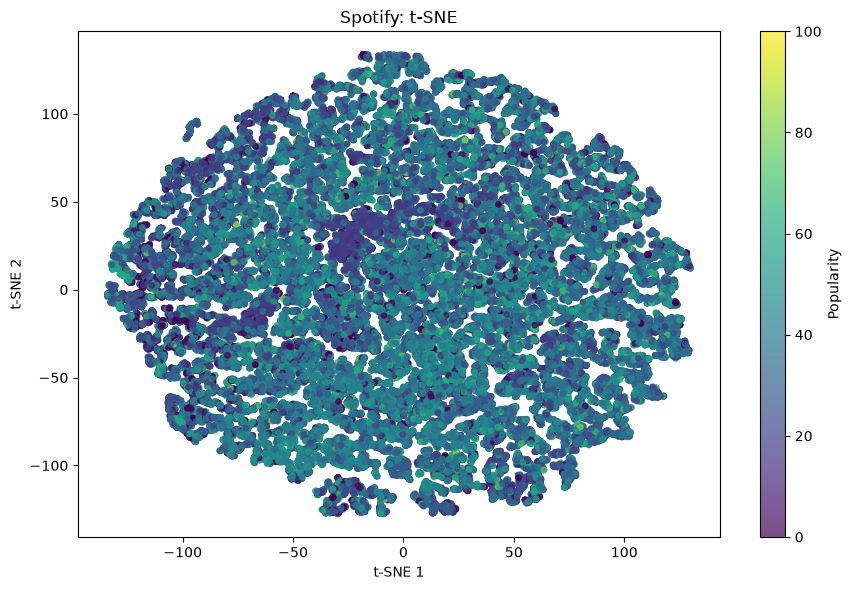

In [65]:
# 7. VẼ BIỂU ĐỒ t-SNE
plt.figure(figsize=(9, 6))

points = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=y.to_numpy(),
    cmap="viridis",
    s=15,
    alpha=0.7
)
plt.colorbar(points, label="Popularity")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("Spotify: t-SNE")
plt.tight_layout()
plt.show()

In [89]:
# Nhóm những dòng có toàn bộ đặc trưng số giống nhau
groups = pd.util.hash_pandas_object(
    df_data[numeric_features],
    index=False
)

# Giữ riêng khoảng 20% để kiểm tra cuối
split_test = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

dev_idx, test_idx = next(
    split_test.split(df_data, groups=groups)
)

development = df_data.iloc[dev_idx]
test = df_data.iloc[test_idx]

# Chia phần còn lại thành train và validation
split_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, val_idx = next(
    split_val.split(
        development,
        groups=groups.iloc[dev_idx]
    )
)

train = development.iloc[train_idx]
validation = development.iloc[val_idx]

In [92]:
# 9. HUẤN LUYỆN LINEAR REGRESSION
model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](2,)","[-0.31, 0.03]"


In [93]:
# 10. DỰ ĐOÁN
y_pred = model.predict(X_test)

In [94]:
# 11. ĐÁNH GIÁ
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nKẾT QUẢ ĐÁNH GIÁ — MINH HỌA")
print(f"MAE:  {mae:.2f}")
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.3f}")



KẾT QUẢ ĐÁNH GIÁ — MINH HỌA
MAE:  17.12
MSE:  417.74
RMSE: 20.44
R²:   -0.000


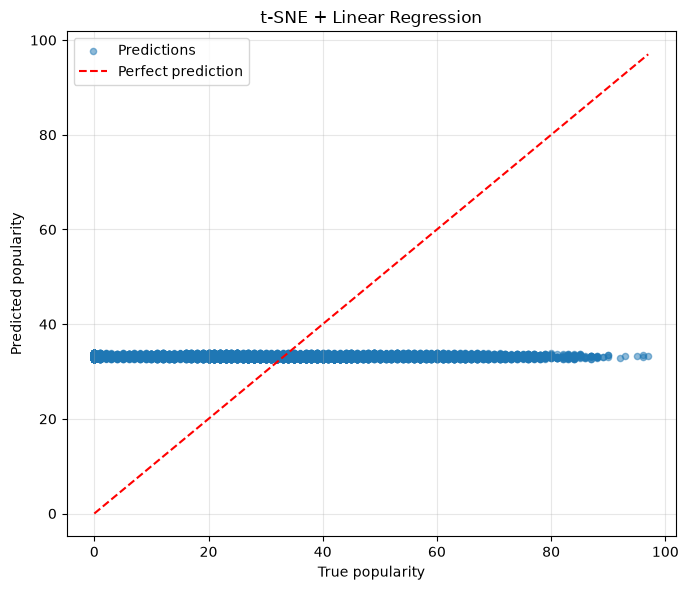

In [95]:
# 13. VẼ BIỂU ĐỒ THỰC TẾ VÀ DỰ ĐOÁN
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred,
    s=20,
    alpha=0.5,
    label="Predictions"
)

plt.plot(
    [low, high],
    [low, high],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("True popularity")
plt.ylabel("Predicted popularity")
plt.title("t-SNE + Linear Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()